In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,classification_report
from sklearn.neural_network import MLPClassifier

print("Loading MNIST dataset...")
X,y= fetch_openml(
    'mnist_784',
     version=1,
     return_X_y = True,
     as_frame=False
)
X= X.astype('float32')
y= y.astype('int')
print("Dataset loaded succcesffully!")
print("Total samples:", X.shape[0])
print("Number of features:", X.shape[1])

X=X/255.0
X=X[:20000]
y=y[:20000]
X_train,X_test, y_train,y_test = train_test_split(
    X,y,
    test_size = 0.2,
    random_state = 42,
    stratify=y
)
print("Training samples:", X_train.shape[0])
print("testing samples :", X_test.shape[0])

activations=['logistic','relu','tanh']
results = {}
training_times = {}
accuracies = {}

for activation in activations:
    print("\n--------------------------")
    print("Training with:", activation)
    print("----------------------------")
    start_time = time.time()
    
    model=MLPClassifier(
          hidden_layer_sizes = (128,),
          activation=activation,
          solver='adam',
          max_iter=100,
          batch_size=128,
          random_state=42,
          verbose=False
    )
    model.fit(X_train, y_train)
    end_time = time.time()
    training_time = end_time - start_time
    y_pred = model.predict(X_test)
    accuracy= accuracy_score(y_test,y_pred)
    results[activation] = model
    training_times[activation] = training_time
    accuracies[activation] = accuracy * 100
    print("Training time: {:.2f} seconds".format(training_time))
    print("Number of iterations:", model.n_iter_)
    print("Test accuracy:{:2f}%".format(accuracy *100))

Loading MNIST dataset...
Dataset loaded succcesffully!
Total samples: 70000
Number of features: 784
Training samples: 16000
testing samples : 4000

--------------------------
Training with: logistic
----------------------------
Training time: 167.22 seconds
Number of iterations: 99
Test accuracy:95.575000%

--------------------------
Training with: relu
----------------------------
Training time: 105.36 seconds
Number of iterations: 56
Test accuracy:96.225000%

--------------------------
Training with: tanh
----------------------------
Training time: 98.95 seconds
Number of iterations: 61
Test accuracy:95.800000%


In [3]:
print("\n----------------------------")
print(" ACTIVATION RUNCTION COMPARISON ")
print("-------------------------------")
print("{:<12} {:<15} {:<15}" .format(
    "Activation", "Time (sec)", "Iterations", "Accuracy(%)"
))
for activation in activations:
    model = results[activation]
    print("{:<12} {:<15.2f} {:<15} {:<15.2f}". format(
              activation,
              training_times[activation],
              model.n_iter_,
            accuracies[activation]
    ))


----------------------------
 ACTIVATION RUNCTION COMPARISON 
-------------------------------
Activation   Time (sec)      Iterations     
logistic     167.22          99              95.58          
relu         105.36          56              96.23          
tanh         98.95           61              95.80          


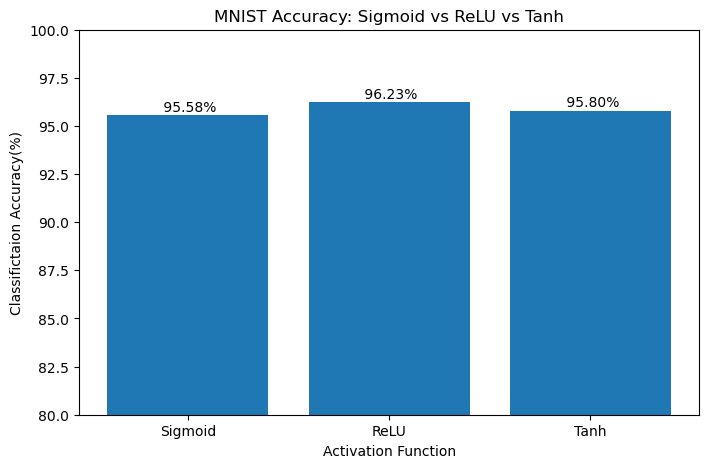

In [6]:
plt.figure(figsize=(8,5))
plt.bar(
    ['Sigmoid','ReLU', 'Tanh'],
    [
        accuracies['logistic'],
        accuracies['relu'],
        accuracies['tanh']
    ]
)
plt.xlabel("Activation Function")
plt.ylabel("Classifictaion Accuracy(%)")
plt.title("MNIST Accuracy: Sigmoid vs ReLU vs Tanh")
plt.ylim(80,100)
for i,value in enumerate([
      accuracies['logistic'],
      accuracies['relu'],
      accuracies['tanh']
]):
    plt.text(i, value +0.2, f"{value: .2f}%",
             ha='center')
plt.show()

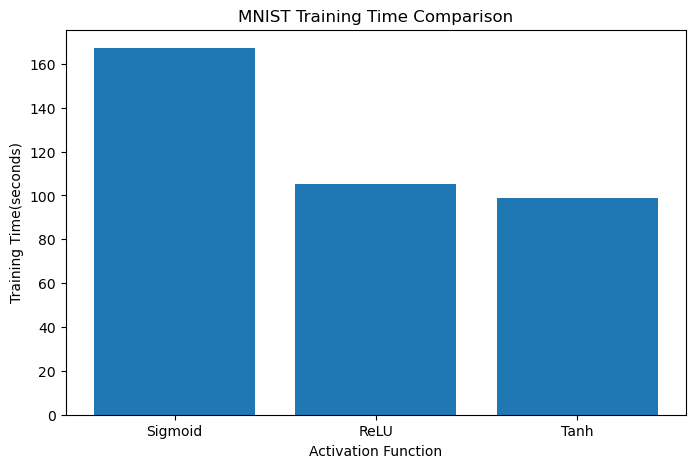

In [7]:
plt.figure(figsize=(8,5))
plt.bar(
    ['Sigmoid','ReLU', 'Tanh'],
    [
       training_times['logistic'],
       training_times['relu'],
       training_times ['tanh']
    ]
)
plt.xlabel("Activation Function")
plt.ylabel("Training Time(seconds)")
plt.title("MNIST Training Time Comparison")
plt.show()

In [ ]:
plt.figure(figsize=(9,5))
for activation in activations:
    model = results[activation]
    plt.plot(
           range(1, len(model.loss_curve_( + 1